# Figure 10: Hawaiʻi Island Only

Standalone reproduction of **Golden Figure E3 and 10** from `Scripts/WW_OL_Final_Data_Analysis.ipynb`.

- Reads the two existing CSVs from the repository's `Data/` folder.
- Reproduces the original impact and MRC calculations.
- Calculates the **statewide mean impact** first, preserving the original vertical reference line.
- Plots **only project areas with a `H-` UID**; retains the original log axes, color scheme, bubble sizes, and horizontal MRC reference line.
- Saves PNG and PDF in this mini-project's `Figures/` folder.

**Does not change any original files or datasets.** Run this notebook from `Scripts/Mini_Projects/Island_Specific_Fig10/`.


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
# Source CSVs from the original Fig. 10 notebook (unchanged).
master = pd.read_csv("../../../Data/Project_Areas_WWOL_Master - Project_Areas_WWOL_Master.csv")
costs = pd.read_csv("../../../Data/Project_Areas_WWOL_Master - Costs.csv")


In [20]:
#### ── BUILD DATAFRAME ───────────────────────────────────────────────────────────
df = master[["UID", "Name", "Status", "Priority_1_Cesspool_Count", "Priority_2_Cesspool_Count", "Priority_3_Cesspool_Count", "Total_Cesspools", "Cost_symbol"]].copy()
df = df.rename(columns={"Priority_1_Cesspool_Count": "p1", "Priority_2_Cesspool_Count": "p2", "Priority_3_Cesspool_Count": "p3", "Total_Cesspools": "total"})


df[["p1","p2","p3","total"]] = df[["p1","p2","p3","total"]].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)
df = df[df["total"] > 0].copy()

# Average priority weight: P1=3, P2=2, P3=1
df["avg_priority_weight"] = (df["p1"]*3 + df["p2"]*2 + df["p3"]*1) / df["total"]

# Impact score
df["impact"] = df["total"] * df["avg_priority_weight"]

# Dominant priority: whichever of p1/p2/p3 is largest
df["dom"] = df[["p1","p2","p3"]].values.argmax(axis=1) + 1  # 1, 2, or 3

# Cost tier
tier_map = {"(1) - $": 1, "(2) - $$": 2, "(3) - $$$": 3, "(4) - $$$$": 4, "(5) - $$$$$": 5}
df["tier"] = df["Cost_symbol"].map(tier_map)

# Planning status shorthand
def status_short(s):
    if "Planned" in str(s): return "P"
    if "Evaluation" in str(s): return "E"
    return "N"
df["status"] = df["Status"].apply(status_short)

# Join MRC from costs
mrc_col = "MRC: Median Relative Cost (dimensionless) "  # trailing space in original
costs_slim = costs[["UID", mrc_col]].copy()
costs_slim[mrc_col] = pd.to_numeric(costs_slim[mrc_col], errors="coerce")
costs_slim = costs_slim.rename(columns={mrc_col: "mrc"})
df = df.merge(costs_slim, on="UID", how="left")
df = df.dropna(subset=["mrc"])

#probably dont need these
#x_quad = 10 ** np.median(np.log10(df["impact"][df["impact"] > 0])); 
#y_quad = 10 ** np.median(np.log10(df["mrc"][df["mrc"] > 0]))
# Use all islands for the original statewide benchmark.
avg_impact = df["impact"].mean()

# Split into 4 county-level dataframes
# Maui County includes both Maui and Molokaʻi
df_hawaii = df[df["UID"].astype(str).str.startswith("H-")].copy()
df_oahu   = df[df["UID"].astype(str).str.startswith("O-")].copy()
df_maui   = df[df["UID"].astype(str).str.startswith(("M-", "Mo-"))].copy()
df_kauai  = df[df["UID"].astype(str).str.startswith("K-")].copy()

print(f"Hawaiʻi Island project areas: {len(df_hawaii)}")
print(f"Oʻahu project areas: {len(df_oahu)}")
print(f"Maui County project areas: {len(df_maui)}")
print(f"Kauaʻi project areas: {len(df_kauai)}")

Hawaiʻi Island project areas: 42
Oʻahu project areas: 22
Maui County project areas: 18
Kauaʻi project areas: 21


In [22]:
# Shared Figure 10 plotting function. All project label positions are supplied by each county cell.
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

dot_color  = {1: "#C0392B", 2: "#E67E22", 3: "#F4D03F"}
edge_color = {1: "#922B21", 2: "#BA6010", 3: "#B7950B"}
text_color = {1: "#7B241C", 2: "#935116", 3: "#7D6608"}

def plot_county(data, county, filename, label_cfg):
    missing = sorted(set(data["UID"]) - set(label_cfg))
    assert not missing, f"Missing label positions for: {missing}"

    fig, ax = plt.subplots(figsize=(16, 11))
    fig.patch.set_facecolor("white")
    ax.set_facecolor("#FAFAFA")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(10, 9000)
    ax.set_ylim(0.15, 4.5)

    # Same reference lines as the original statewide figure.
    ax.axhline(0.75, color="black", linewidth=0.8, linestyle="--", zorder=1)
    ax.axvline(avg_impact, color="black", linewidth=0.8, linestyle="--", zorder=1)

    # P3 first so high-priority P1 circles are drawn on top.
    for dom in [3, 2, 1]:
        subset = data[data["dom"] == dom]
        ax.scatter(subset["impact"], subset["mrc"],
                   s=35 + np.sqrt(subset["total"]) * 14,
                   color=dot_color[dom], edgecolors=edge_color[dom],
                   linewidths=0.8, zorder=3)

    # Hand-adjustable position for EVERY project area, keyed by UID.
    for _, row in data.iterrows():
        label, dx, dy, ha = label_cfg[row["UID"]]
        ax.annotate(label, (row["impact"], row["mrc"]),
                    xytext=(dx, dy), textcoords="offset points",
                    fontsize=9, ha=ha, va="center",
                    color=text_color[int(row["dom"])], zorder=5,
                    arrowprops=dict(arrowstyle="-", lw=0.6, alpha=0.5,
                                    color=text_color[int(row["dom"])]))

    ax.set_yticks([0.2, 0.5, 1, 2, 3])
    ax.set_xlabel("Impact score (log scale) - cesspool count × avg HCPT priority weight", fontsize=16)
    ax.set_ylabel("MRC - Median Relative Cost (log scale)", fontsize=16)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}" if x >= 1 else ""))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1f}x"))
    for spine in ax.spines.values():
        spine.set_edgecolor("#DDDDDD")
    ax.tick_params(colors="#888888", labelsize=10)
    ax.grid(True, which="major", color="#E8E8E8", linewidth=0.5)
    ax.grid(True, which="minor", color="#F0F0F0", linewidth=0.3)

    ax.text(5500, 0.23, "high impact\nlow cost", fontsize=16, ha="right", va="bottom", style="italic")
    ax.text(12, 0.18, "low impact\nlow cost", fontsize=16, ha="left", va="bottom", style="italic")
    ax.text(5500, 2.0, "high impact\nhigh cost", fontsize=16, ha="right", va="top", style="italic")
    ax.text(12, 4.0, "low impact\nhigh cost", fontsize=16, ha="left", va="top", style="italic")

    legend_handles = [
        plt.Line2D([0], [0], marker="o", color="w",
                   markerfacecolor=dot_color[d], markeredgecolor=edge_color[d],
                   markersize=8, label=f"Dominant Priority {d}") for d in [1, 2, 3]
    ]
    ax.legend(handles=legend_handles, fontsize=12, frameon=True,
              edgecolor="black", loc="upper right")
    ax.set_title(f"{county} Project Area Feasibility: Cost vs. Benefits", fontsize=18, pad=12)

    Path("Figures").mkdir(exist_ok=True)
    fig.savefig(f"Figures/Fig10_{filename}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"Figures/Fig10_{filename}.pdf", bbox_inches="tight")
    plt.show()

    # Complete project table: original input counts plus every key figure variable.
    table = data[["UID", "Name", "Status", "p1", "p2", "p3", "total",
                  "dom", "avg_priority_weight", "impact", "mrc", "tier", "Cost_symbol"]].copy()
    table.insert(2, "Island", table["UID"].str.split("-").str[0].map(
        {"H": "Hawaiʻi", "O": "Oʻahu", "M": "Maui", "Mo": "Molokaʻi", "K": "Kauaʻi"}))
    table = table.rename(columns={
        "UID": "Project ID", "Name": "Project Area", "Status": "Planning Status",
        "p1": "Priority 1 Cesspools", "p2": "Priority 2 Cesspools",
        "p3": "Priority 3 Cesspools", "total": "Total Cesspools",
        "dom": "Dominant Priority", "avg_priority_weight": "Avg Priority Weight",
        "impact": "Impact Score", "mrc": "MRC (Relative Cost)",
        "tier": "Cost Tier (1-5)", "Cost_symbol": "Cost Tier Symbol"
    }).sort_values("Impact Score", ascending=False).reset_index(drop=True)

    Path("Tables").mkdir(exist_ok=True)
    table.to_csv(f"Tables/Fig10_{filename}_Projects.csv", index=False)
    with pd.ExcelWriter(f"Tables/Fig10_{filename}_Projects.xlsx", engine="openpyxl") as writer:
        table.to_excel(writer, sheet_name="Project Areas", index=False)
        ws = writer.sheets["Project Areas"]
        ws.freeze_panes = "D2"
        ws.auto_filter.ref = ws.dimensions
        ws.sheet_view.showGridLines = False
        for cell in ws[1]:
            cell.fill = PatternFill("solid", fgColor="183B56")
            cell.font = Font(color="FFFFFF", bold=True)
            cell.alignment = Alignment(wrap_text=True, vertical="center")
        ws.row_dimensions[1].height = 34
        for col_num, col_name in enumerate(table.columns, 1):
            width = max(len(str(col_name)) + 2, table[col_name].astype(str).str.len().quantile(0.9) + 2)
            ws.column_dimensions[get_column_letter(col_num)].width = min(34, max(14, int(width)))
            if col_name in ("Avg Priority Weight", "MRC (Relative Cost)"):
                for row in ws.iter_rows(min_row=2, min_col=col_num, max_col=col_num):
                    row[0].number_format = "0.000"
            elif col_name in ("Impact Score", "Total Cesspools", "Priority 1 Cesspools",
                              "Priority 2 Cesspools", "Priority 3 Cesspools"):
                for row in ws.iter_rows(min_row=2, min_col=col_num, max_col=col_num):
                    row[0].number_format = "#,##0"

        notes = writer.book.create_sheet("Notes")
        for key, value in [
            ("Figure", f"Golden Figure E3 and 10: {county}"),
            ("Impact Score", "3 × Priority 1 count + 2 × Priority 2 count + Priority 3 count"),
            ("MRC", "Median Relative Cost; dimensionless. It is not a dollar estimate."),
            ("Dominant Priority", "Priority group with the most cesspools in the project area."),
            ("Chart reference line", f"Statewide mean impact score: {avg_impact:.3f}"),
            ("Source & methods", "https://github.com/cshuler/WW_Overlay_2024"),
        ]:
            notes.append([key, value])
        notes.column_dimensions["A"].width = 26
        notes.column_dimensions["B"].width = 85
        for cell in notes["A"]:
            cell.font = Font(bold=True, color="183B56")

    print(f"{county}: {len(table)} project areas | Figures/Fig10_{filename} (PNG, PDF) | Tables/Fig10_{filename}_Projects (CSV, XLSX)")
    return table


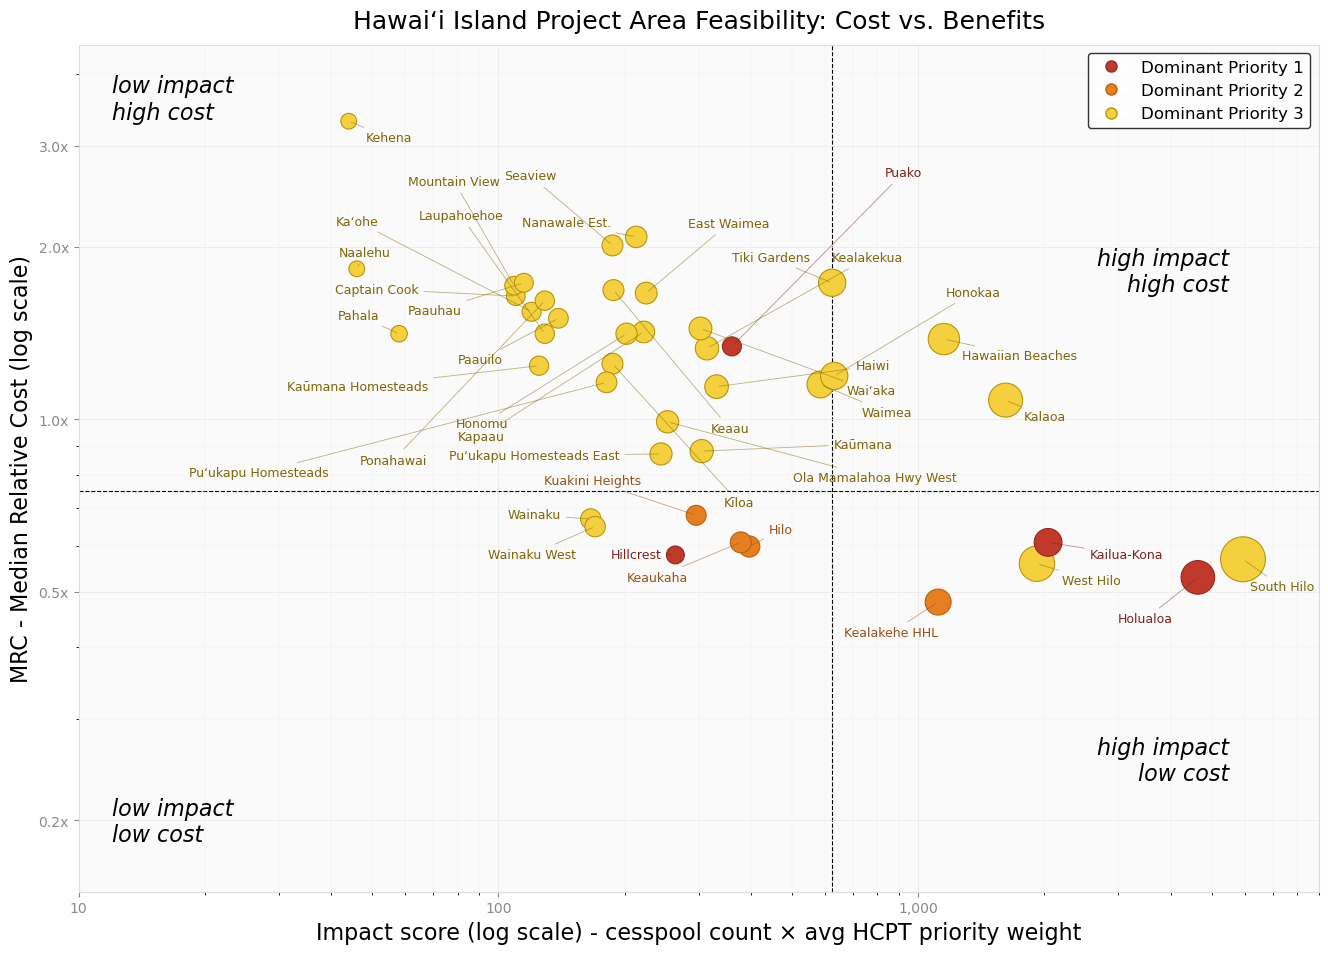

Hawaiʻi Island: 42 project areas | Figures/Fig10_Hawaii_Island (PNG, PDF) | Tables/Fig10_Hawaii_Island_Projects (CSV, XLSX)


,Project ID,Project Area,Island,Planning Status,Priority 1 Cesspools,Priority 2 Cesspools,Priority 3 Cesspools,Total Cesspools,Dominant Priority,Avg Priority Weight,Impact Score,MRC (Relative Cost),Cost Tier (1-5),Cost Tier Symbol
0,H-14,South Hilo,Hawaiʻi,No Active Plans (N),0,737,4469,5206,3,1.141567,5943.0,0.57,3,(3) - $$$
1,H-17,Holualoa,Hawaiʻi,No Active Plans (N),1543,5,1,1549,1,2.995481,4640.0,0.53,3,(3) - $$$
2,H-4,Kailua-Kona,Hawaiʻi,No Active Plans (N),680,0,0,680,1,3.000000,2040.0,0.61,3,(3) - $$$
3,H-12,West Hilo,Hawaiʻi,No Active Plans (N),0,0,1919,1919,3,1.000000,1919.0,0.56,3,(3) - $$$
4,H-26,Kalaoa,Hawaiʻi,No Active Plans (N),0,0,1616,1616,3,1.000000,1616.0,1.08,4,(4) - $$$$


In [50]:
# Hawaiʻi Island: editable positions (label, x offset, y offset, alignment)
label_cfg_hawaii = {
    "H-1":  ("Pahala", -14, 13, "right"),
    "H-2":  ("Naalehu", -13, 12, "left"),
    "H-3":  ("Hillcrest", -10, 0, "right"),
    "H-4":  ("Kailua-Kona", 30, -9, "left"),
    "H-5":  ("Kealakehe HHL", 0, -22, "right"),
    "H-6":  ("Honokaa", 80, 60, "left"),
    "H-7":  ("Paauhau", -45, -20, "right"),
    "H-8":  ("Honomu", -85, -65, "right"),
    "H-9":  ("Wainaku West", -14, -20, "right"),
    "H-10": ("Wainaku", -60, 3, "left"),
    "H-11": ("Kaūmana", 95, 5, "left"),
    "H-12": ("West Hilo", 18, -12, "left"),
    "H-13": ("Hilo", 14, 12, "left"),
    "H-14": ("South Hilo", 5, -20, "left"),
    "H-15": ("Keaukaha", -38, -25, "right"),
    "H-16": ("Kuakini Heights", -40, 25, "right"),
    "H-17": ("Holualoa", -18, -30, "right"),
    "H-18": ("Hawaiian Beaches", 13, -12, "left"),
    "H-19": ("Nanawale Est.", -18, 10, "right"),
    "H-20": ("Seaview", -40, 50, "right"),
    "H-21": ("Kehena", 12, -12, "left"),
    "H-22": ("Kaʻohe", -110, 65, "right"),
    "H-23": ("Kīloa", 80, -100, "left"),
    "H-24": ("Captain Cook", -70, 5, "right"),
    "H-25": ("Kealakekua", 90, 65, "left"),
    "H-26": ("Kalaoa", 13, -12, "left"),
    "H-27": ("Haiwi", 100, 15, "left"),
    "H-28": ("Kapaau", -100, -75, "right"),
    "H-29": ("Puʻukapu Homesteads", -200, -65, "right"),
    "H-30": ("Puʻukapu Homesteads East", -30, -1, "right"),
    "H-31": ("Ola Mamalahoa Hwy West", 90, -40, "left"),
    "H-32": ("Paauilo", -40, -30, "right"),
    "H-33": ("Laupahoehoe", -30, 85, "right"),
    "H-34": ("Ponahawai", -85, -115, "right"),
    "H-35": ("Kaūmana Homesteads", -80, -15, "right"),
    "H-36": ("Keaau", 70, -100, "left"),
    "H-37": ("Mountain View", -10, 75, "right"),
    "H-38": ("Tiki Gardens", -16, 18, "right"),
    "H-39": ("Waiʻaka", 105, -45, "left"),
    "H-40": ("Waimea", 30, -20, "left"),
    "H-41": ("East Waimea", 30, 50, "left"),
    "H-42": ("Puako", 110, 125, "left"),
}

table_hawaii = plot_county(df_hawaii, 'Hawaiʻi Island', 'Hawaii_Island', label_cfg_hawaii)
table_hawaii.head(5)

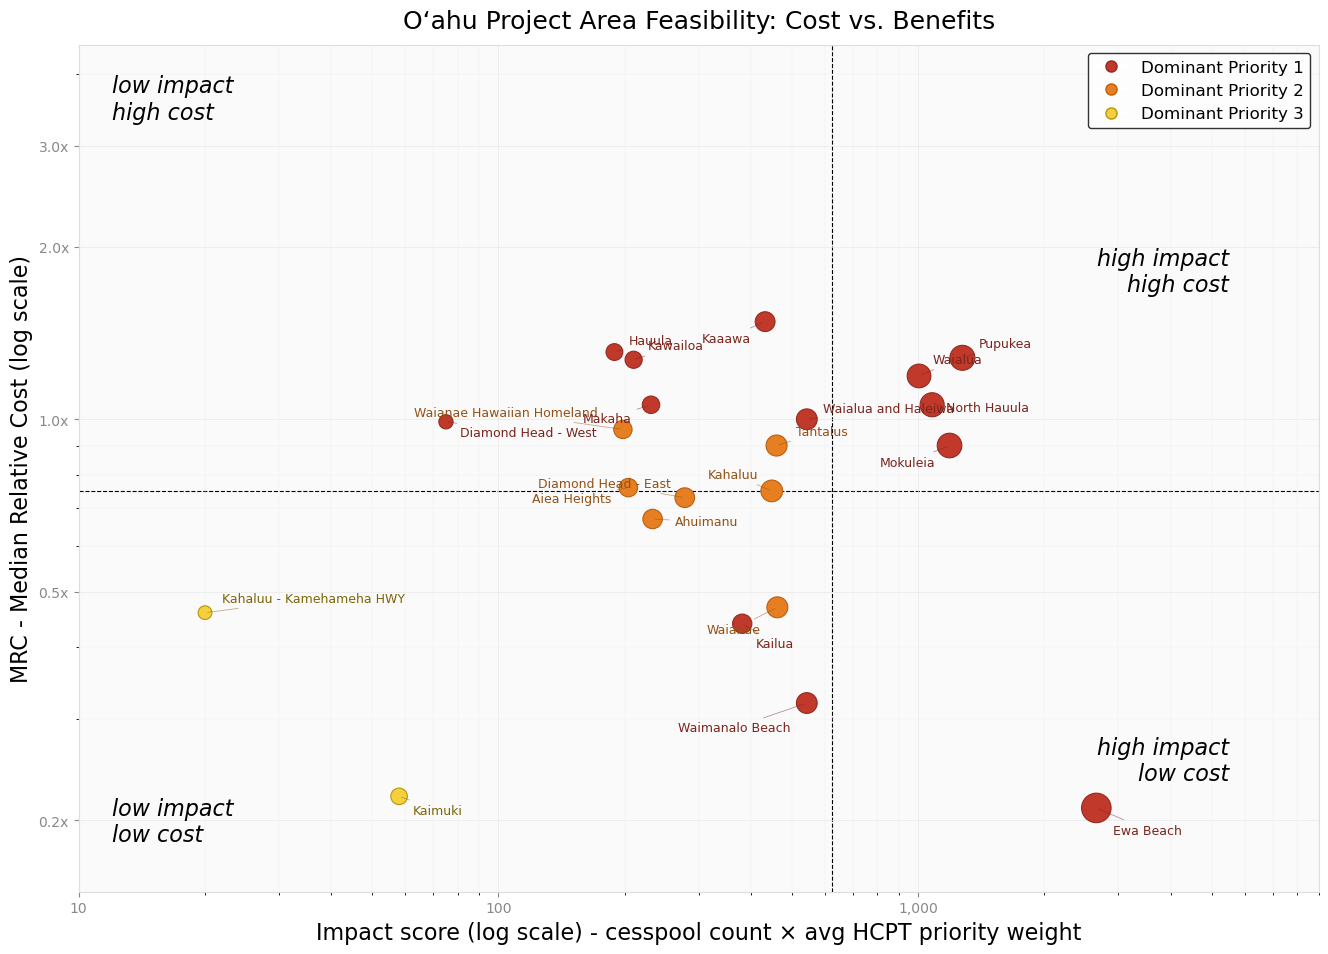

Oʻahu: 22 project areas | Figures/Fig10_Oahu (PNG, PDF) | Tables/Fig10_Oahu_Projects (CSV, XLSX)


,Project ID,Project Area,Island,Planning Status,Priority 1 Cesspools,Priority 2 Cesspools,Priority 3 Cesspools,Total Cesspools,Dominant Priority,Avg Priority Weight,Impact Score,MRC (Relative Cost),Cost Tier (1-5),Cost Tier Symbol
0,O-11,Ewa Beach,Oʻahu,Planned or Underway (P),886,0,0,886,1,3.0,2658.0,0.21,1,(1) - $
1,O-20,Pupukea,Oʻahu,No Active Plans (N),425,0,0,425,1,3.0,1275.0,1.28,4,(4) - $$$$
2,O-8,Mokuleia,Oʻahu,Under Evaluation (E),396,0,0,396,1,3.0,1188.0,0.90,4,(4) - $$$$
3,O-5,North Hauula,Oʻahu,No Active Plans (N),360,0,0,360,1,3.0,1080.0,1.06,4,(4) - $$$$
4,O-7,Waialua,Oʻahu,Under Evaluation (E),335,0,0,335,1,3.0,1005.0,1.19,4,(4) - $$$$


In [42]:
# Oʻahu: editable positions (label, x offset, y offset, alignment)
label_cfg_oahu = {
    "O-1":  ("Waimanalo Beach", -12, -18, "right"),
    "O-2":  ("Kailua", 10, -14, "left"),
    "O-3":  ("Ahuimanu", 16, -2, "left"),
    "O-4":  ("Kahaluu", -10, 12, "right"),
    "O-5":  ("North Hauula", 10, -2, "left"),
    "O-6":  ("Waialua and Haleiwa", 12, 8, "left"),
    "O-7":  ("Waialua", 10, 12, "left"),
    "O-8":  ("Mokuleia", -10, -12, "right"),
    "O-9":  ("Makaha", -14, -10, "right"),
    "O-10": ("Waianae", -12, -16, "right"),
    "O-11": ("Ewa Beach", 12, -16, "left"),
    "O-12": ("Kaimuki", 10, -10, "left"),
    "O-13": ("Diamond Head - West", 10, -8, "left"),
    "O-14": ("Diamond Head - East", -10, 10, "right"),
    "O-15": ("Tantalus", 14, 10, "left"),
    "O-16": ("Aiea Heights", -12, -8, "right"),
    "O-17": ("Kahaluu - Kamehameha HWY", 12, 10, "left"),
    "O-18": ("Kaaawa", -10, -12, "right"),
    "O-19": ("Hauula", 10, 8, "left"),
    "O-20": ("Pupukea", 12, 10, "left"),
    "O-21": ("Kawailoa", 10, 10, "left"),
    "O-22": ("Waianae Hawaiian Homeland", -18, 12, "right"),
}

table_oahu = plot_county(df_oahu, 'Oʻahu', 'Oahu', label_cfg_oahu)
table_oahu.head(5)

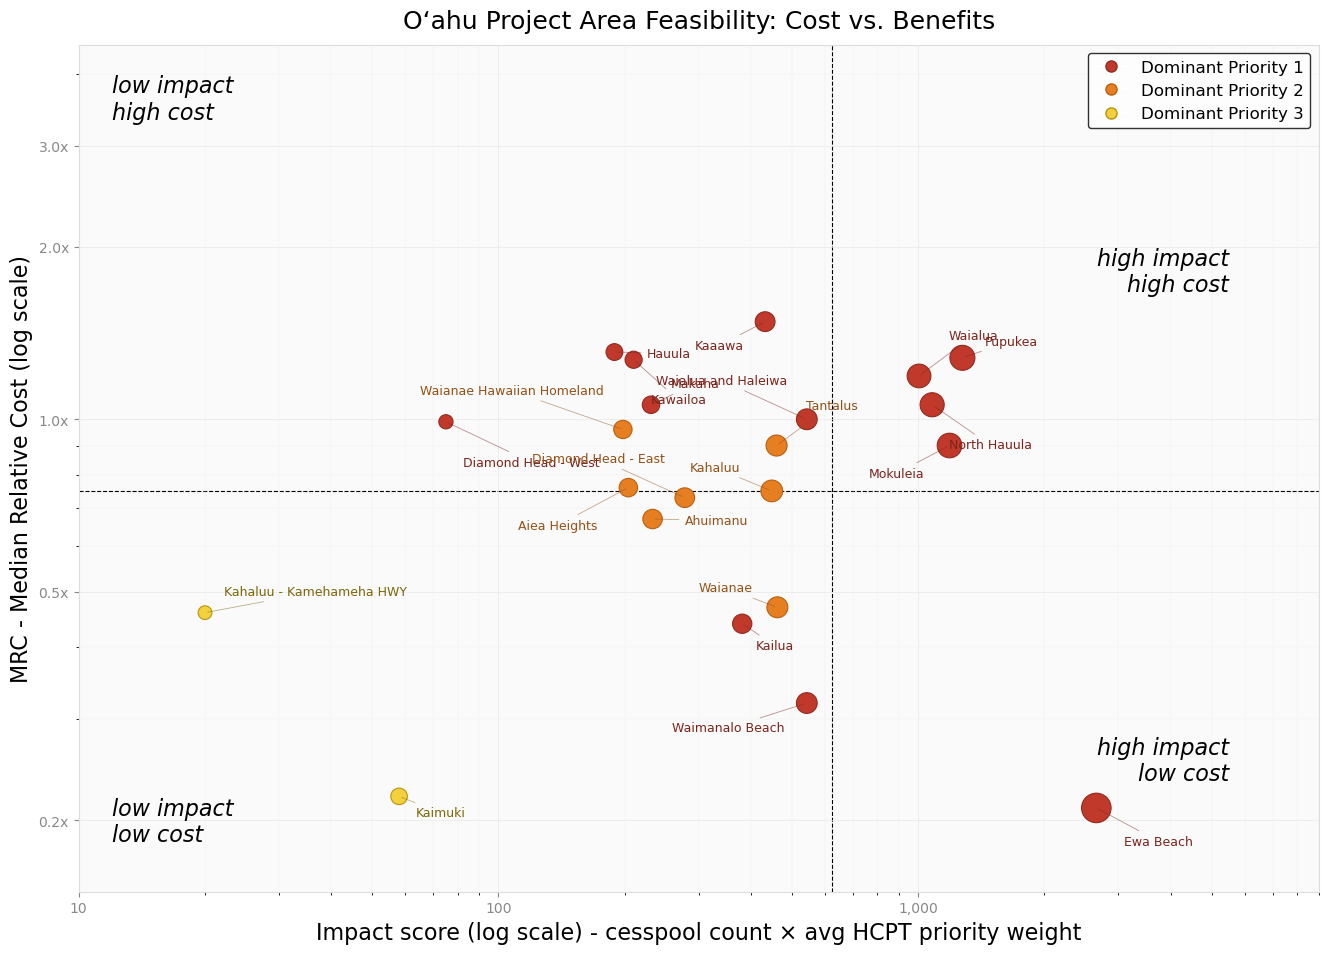

Oʻahu: 22 project areas | Figures/Fig10_Oahu (PNG, PDF) | Tables/Fig10_Oahu_Projects (CSV, XLSX)


,Project ID,Project Area,Island,Planning Status,Priority 1 Cesspools,Priority 2 Cesspools,Priority 3 Cesspools,Total Cesspools,Dominant Priority,Avg Priority Weight,Impact Score,MRC (Relative Cost),Cost Tier (1-5),Cost Tier Symbol
0,O-11,Ewa Beach,Oʻahu,Planned or Underway (P),886,0,0,886,1,3.0,2658.0,0.21,1,(1) - $
1,O-20,Pupukea,Oʻahu,No Active Plans (N),425,0,0,425,1,3.0,1275.0,1.28,4,(4) - $$$$
2,O-8,Mokuleia,Oʻahu,Under Evaluation (E),396,0,0,396,1,3.0,1188.0,0.90,4,(4) - $$$$
3,O-5,North Hauula,Oʻahu,No Active Plans (N),360,0,0,360,1,3.0,1080.0,1.06,4,(4) - $$$$
4,O-7,Waialua,Oʻahu,Under Evaluation (E),335,0,0,335,1,3.0,1005.0,1.19,4,(4) - $$$$


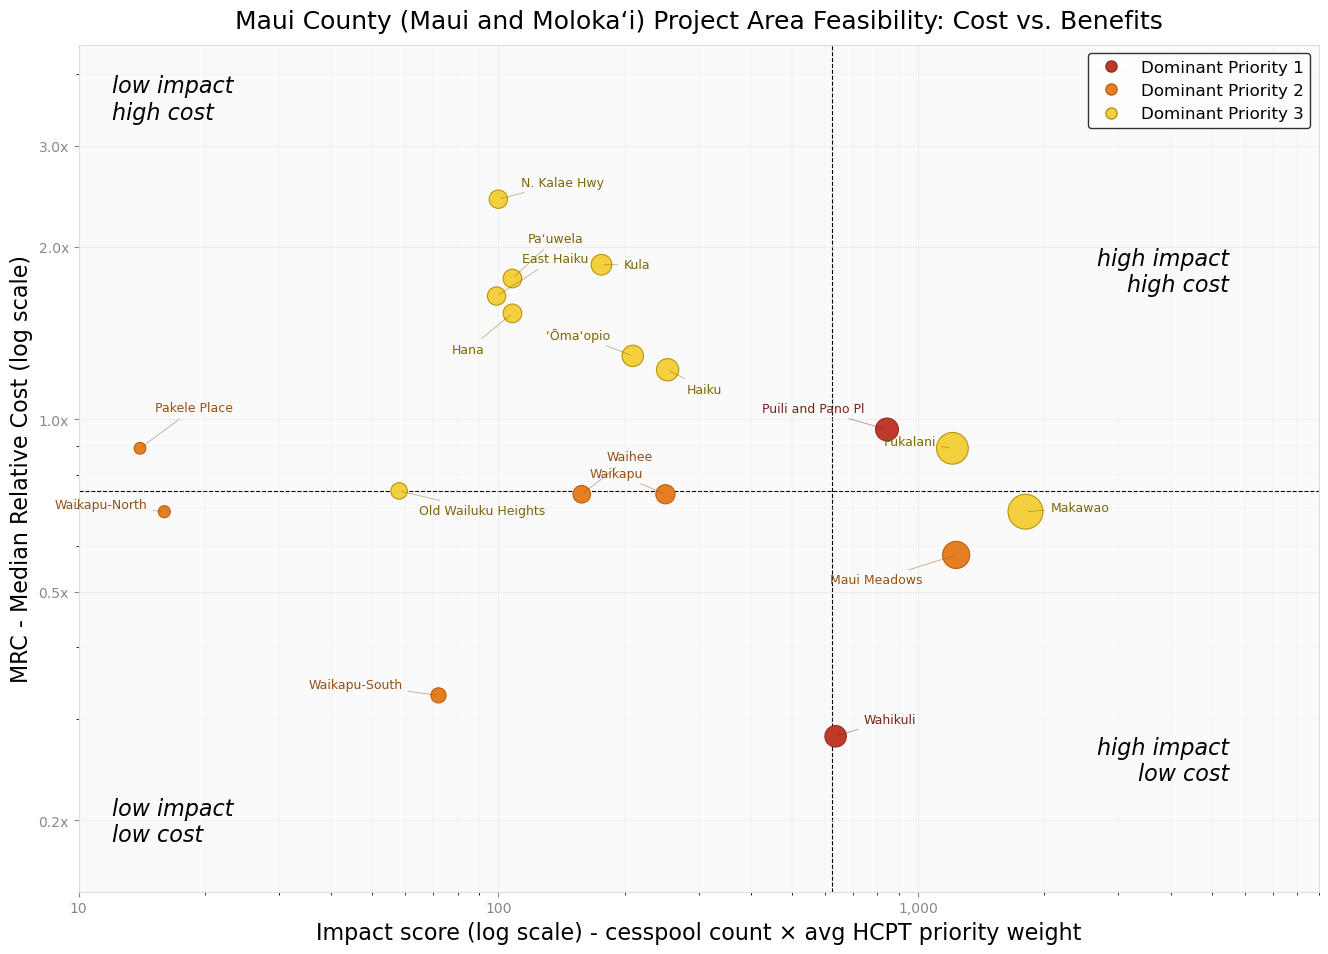

Maui County (Maui and Molokaʻi): 18 project areas | Figures/Fig10_Maui_County (PNG, PDF) | Tables/Fig10_Maui_County_Projects (CSV, XLSX)


,Project ID,Project Area,Island,Planning Status,Priority 1 Cesspools,Priority 2 Cesspools,Priority 3 Cesspools,Total Cesspools,Dominant Priority,Avg Priority Weight,Impact Score,MRC (Relative Cost),Cost Tier (1-5),Cost Tier Symbol
0,M-15,Makawao,Maui,No Active Plans (N),0,0,1802,1802,3,1.0,1802.0,0.69,3,(3) - $$$
1,M-7,Maui Meadows,Maui,No Active Plans (N),0,616,0,616,2,2.0,1232.0,0.58,3,(3) - $$$
2,M-14,Pukalani,Maui,No Active Plans (N),0,0,1207,1207,3,1.0,1207.0,0.89,4,(4) - $$$$
3,Mo-1,Puili and Pano Pl,Molokaʻi,No Active Plans (N),281,0,0,281,1,3.0,843.0,0.96,4,(4) - $$$$
4,M-4,Wahikuli,Maui,Under Evaluation (E),212,0,0,212,1,3.0,636.0,0.28,1,(1) - $


In [31]:
# Maui County (Maui and Molokaʻi): editable positions (label, x offset, y offset, alignment)
label_cfg_maui = {
    'M-1': ('Waikapu', -16,  15, 'right'),
    'M-2': ('Old Wailuku Heights',  14, -14, 'left'),
    'M-3': ('Waihee',  18,  27, 'left'),
    'M-4': ('Wahikuli',  20,  12, 'left'),
    'M-5': ('Pakele Place',  11,  29, 'left'),
    'M-6': ('Waikapu-North', -12,   5, 'right'),
    'M-7': ('Maui Meadows', -24, -18, 'right'),
    'M-8': ('Kula',  16,   0, 'left'),
    'M-9': ('ʻŌmaʻopio', -16,  15, 'right'),
    'M-10': ('Haiku',  14, -14, 'left'),
    'M-11': ('East Haiku',  18,  27, 'left'),
    'M-12': ('Hana', -20, -26, 'right'),
    'M-13': ('Paʻuwela',  11,  29, 'left'),
    'M-14': ('Pukalani', -12,   5, 'right'),
    'M-15': ('Makawao',  18,   3, 'left'),
    'M-16': ('Waikapu-South', -26,   8, 'right'),
    'Mo-1': ('Puili and Pano Pl', -16,  15, 'right'),
    'Mo-2': ('N. Kalae Hwy',  16,  12, 'left'),
}

table_maui = plot_county(df_maui, 'Maui County (Maui and Molokaʻi)', 'Maui_County', label_cfg_maui)
table_maui.head(5)

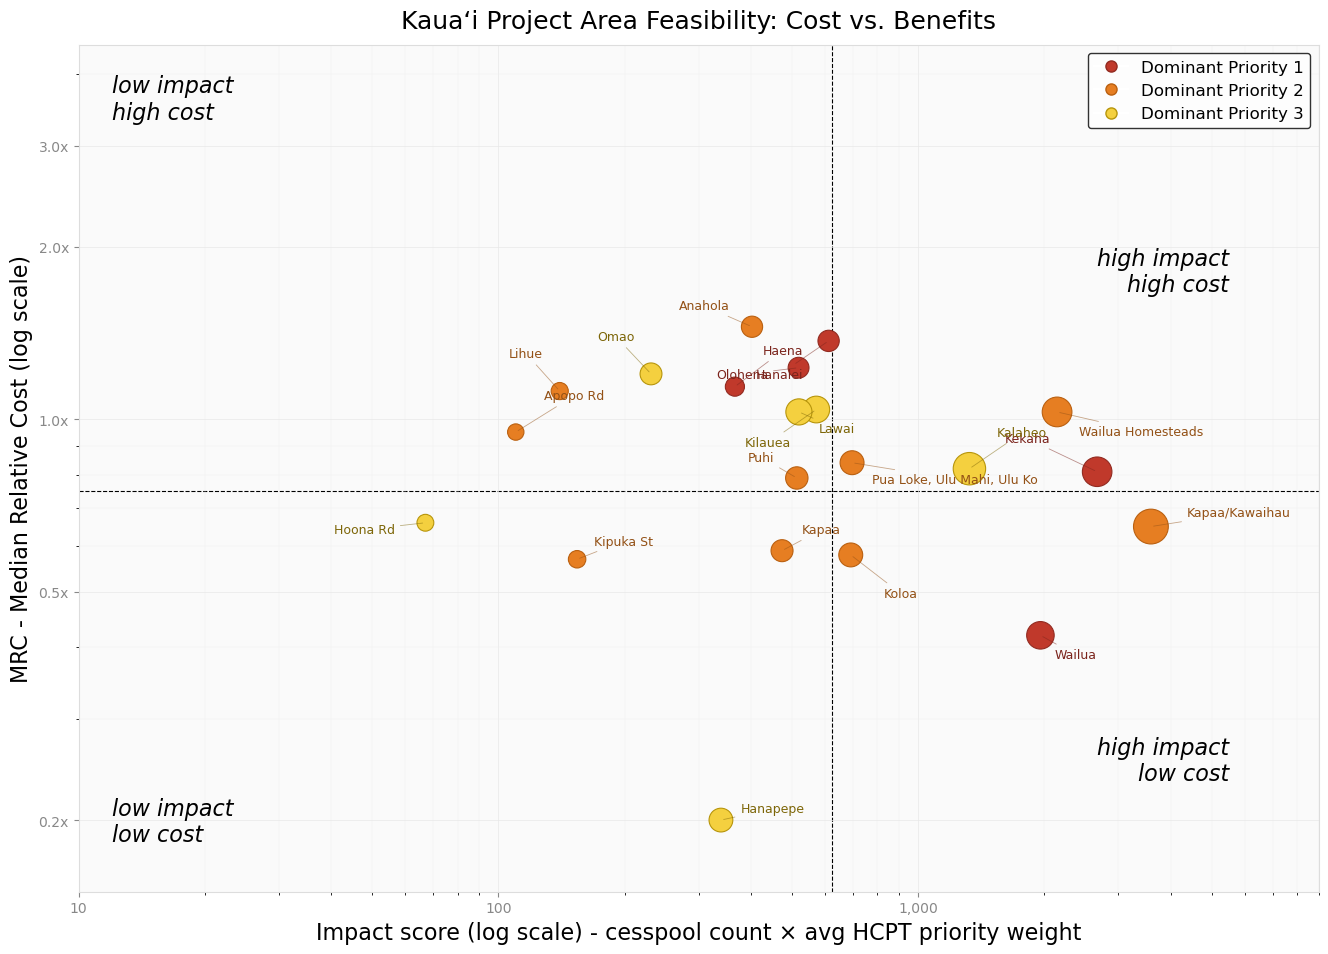

Kauaʻi: 21 project areas | Figures/Fig10_Kauai (PNG, PDF) | Tables/Fig10_Kauai_Projects (CSV, XLSX)


,Project ID,Project Area,Island,Planning Status,Priority 1 Cesspools,Priority 2 Cesspools,Priority 3 Cesspools,Total Cesspools,Dominant Priority,Avg Priority Weight,Impact Score,MRC (Relative Cost),Cost Tier (1-5),Cost Tier Symbol
0,K-2,Kapaa/Kawaihau,Kauaʻi,No Active Plans (N),0,1793,0,1793,2,2.000000,3586.0,0.65,3,(3) - $$$
1,K-1,Kekaha,Kauaʻi,No Active Plans (N),890,0,0,890,1,3.000000,2670.0,0.81,4,(4) - $$$$
2,K-7,Wailua Homesteads,Kauaʻi,No Active Plans (N),325,584,0,909,2,2.357536,2143.0,1.03,4,(4) - $$$$
3,K-5,Wailua,Kauaʻi,No Active Plans (N),652,0,0,652,1,3.000000,1956.0,0.42,2,(2) - $$
4,K-19,Kalaheo,Kauaʻi,No Active Plans (N),0,0,1325,1325,3,1.000000,1325.0,0.82,4,(4) - $$$$


In [32]:
# Kauaʻi: editable positions (label, x offset, y offset, alignment)
label_cfg_kauai = {
    'K-1': ('Kekaha', -34,  24, 'right'),
    'K-2': ('Kapaa/Kawaihau',  26,  10, 'left'),
    'K-3': ('Apopo Rd',  20,  26, 'left'),
    'K-4': ('Kapaa',  14,  15, 'left'),
    'K-5': ('Wailua',  10, -14, 'left'),
    'K-6': ('Olohena', -22,  -5, 'right'),
    'K-7': ('Wailua Homesteads',  16, -14, 'left'),
    'K-8': ('Lihue', -12,  27, 'right'),
    'K-9': ('Pua Loke, Ulu Mahi, Ulu Ko',  14, -12, 'left'),
    'K-10': ('Puhi', -16,  15, 'right'),
    'K-11': ('Haena',  20,  26, 'left'),
    'K-12': ('Kilauea', -18, -24, 'right'),
    'K-13': ('Kipuka St',  12,  13, 'left'),
    'K-14': ('Hoona Rd', -22,  -5, 'right'),
    'K-15': ('Koloa',  24, -28, 'left'),
    'K-16': ('Omao', -12,  27, 'right'),
    'K-17': ('Lawai',  14, -12, 'left'),
    'K-18': ('Anahola', -16,  15, 'right'),
    'K-19': ('Kalaheo',  20,  26, 'left'),
    'K-20': ('Hanalei', -18, -24, 'right'),
    'K-21': ('Hanapepe',  14,   8, 'left'),
}

table_kauai = plot_county(df_kauai, 'Kauaʻi', 'Kauai', label_cfg_kauai)
table_kauai.head(5)